[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/projections-and-least-squares/notebook.ipynb)

# Projections and Least Squares: hands-on

This notebook goes with the [topic README](README.md). You will project a vector onto a line and onto a plane, check the properties of the projection matrix, solve least-squares problems four ways, fit a line and polynomials to noisy points, see why high-degree fits overfit, compare the accuracy of the normal equations with QR, handle collinear columns, and remove a direction from a cloud of points. All data are synthetic. It uses NumPy, Matplotlib, and `scipy.linalg`, and runs in a few seconds on a CPU.

Numerical checks such as "$P^2 = P$" hold only up to rounding error, so we compare with `np.allclose`, never with `==`.

In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=4, suppress=True)

## 1. Projection onto a line

To project $\mathbf{b}$ onto the line through $\mathbf{a}$, find the multiple $\hat{x}\,\mathbf{a}$ that is closest to $\mathbf{b}$. The error $\mathbf{e} = \mathbf{b} - \hat{x}\,\mathbf{a}$ must be perpendicular to $\mathbf{a}$, which gives $\hat{x} = \dfrac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{a}\cdot\mathbf{a}}$.

In [2]:
a = np.array([3.0, 4.0])
b = np.array([5.0, 5.0])

x_hat = (a @ b) / (a @ a)
p = x_hat * a                          # the projection of b onto the line
e = b - p                              # the error vector
print("x_hat =", x_hat, "| p =", p, "| e =", e)
print("e . a =", round(e @ a, 12), "(perpendicular)")

P = np.outer(a, a) / (a @ a)           # the projection matrix for this line
print("P =\n", P)
print("P b = p        :", np.allclose(P @ b, p))
print("P P = P        :", np.allclose(P @ P, P))
print("P^T = P        :", np.allclose(P.T, P))
print("trace(P) = ", round(np.trace(P), 10), "(the dimension of the line)")

x_hat = 1.4 | p = [4.2 5.6] | e = [ 0.8 -0.6]
e . a = 0.0 (perpendicular)
P =
 [[0.36 0.48]
 [0.48 0.64]]
P b = p        : True
P P = P        : True
P^T = P        : True
trace(P) =  1.0 (the dimension of the line)


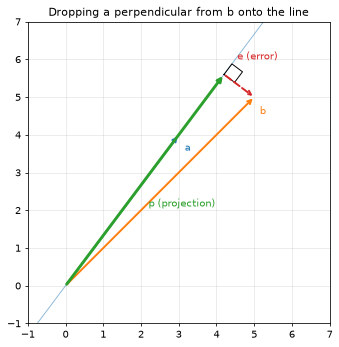

In [3]:
fig, ax = plt.subplots(figsize=(5.6, 5.6))
t = np.linspace(-1, 2.2, 10)
ax.plot(t * a[0], t * a[1], color="C0", lw=1, alpha=0.5)
def arrow(vec, start=(0, 0), color="k", ls="-", lw=2):
    ax.annotate("", xy=np.add(start, vec), xytext=start, arrowprops=dict(arrowstyle="->", color=color, lw=lw, ls=ls))
arrow(a, color="C0"); arrow(b, color="C1"); arrow(p, color="C2", lw=3); arrow(e, start=p, color="C3", ls="--")
u = a / np.linalg.norm(a); w = e / np.linalg.norm(e)
s = 0.35
corner = np.array([p, p + s * u, p + s * u + s * w, p + s * w, p])         # a little square: the right angle
ax.plot(*corner.T, color="k", lw=1)
ax.text(*(a * 1.02 + [0.1, -0.5]), "a", color="C0")
ax.text(*(b + [0.15, -0.45]), "b", color="C1")
ax.text(*(p * 0.5 + [0.1, -0.7]), "p (projection)", color="C2")
ax.text(*(p + [0.35, 0.4]), "e (error)", color="C3")
ax.set_xlim(-1, 7); ax.set_ylim(-1, 7); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title("Dropping a perpendicular from b onto the line")
plt.show()

## 2. Projection onto a plane (a subspace)

For a matrix $A$ with independent columns, the **closest point to $\mathbf{b}$ in the column space** is $\mathbf{p} = A\hat{\mathbf{x}}$, where the error $\mathbf{e} = \mathbf{b} - A\hat{\mathbf{x}}$ is perpendicular to every column of $A$. That condition, $A^\top\mathbf{e} = \mathbf{0}$, gives the **normal equations** $A^\top A\,\hat{\mathbf{x}} = A^\top\mathbf{b}$.

In [4]:
A = np.array([[1.0, 0.0],
              [1.0, 1.0],
              [1.0, 2.0]])            # two columns span a plane in R^3
b = np.array([1.0, 3.0, 4.0])

x_hat = np.linalg.solve(A.T @ A, A.T @ b)      # the normal equations
p = A @ x_hat
e = b - p
print("x_hat =", x_hat)
print("p =", p)
print("e =", e)
print("A^T e =", np.round(A.T @ e, 12) + 0.0, "(the error is perpendicular to both columns)")

P = A @ np.linalg.inv(A.T @ A) @ A.T           # projection matrix (for study, not for computing!)
print("\n6 P =\n", np.round(6 * P, 6))
print("P b = p       :", np.allclose(P @ b, p))
print("P P = P       :", np.allclose(P @ P, P))
print("P^T = P       :", np.allclose(P.T, P))
print("trace(P) =", round(np.trace(P), 10), "= dimension of the column space")
print("(I - P) b = e :", np.allclose((np.eye(3) - P) @ b, e), "| A^T (I - P) = 0:", np.allclose(A.T @ (np.eye(3) - P), 0))

x_hat = [1.1667 1.5   ]
p = [1.1667 2.6667 4.1667]
e = [-0.1667  0.3333 -0.1667]
A^T e = [0. 0.] (the error is perpendicular to both columns)

6 P =
 [[ 5.  2. -1.]
 [ 2.  2.  2.]
 [-1.  2.  5.]]
P b = p       : True
P P = P       : True
P^T = P       : True
trace(P) = 2.0 = dimension of the column space
(I - P) b = e : True | A^T (I - P) = 0: True


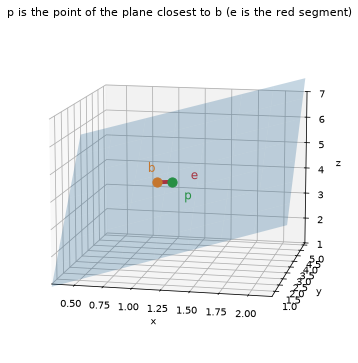

In [5]:
s, t = np.meshgrid(np.linspace(0.3, 2.2, 8), np.linspace(0.3, 2.7, 8))
plane = s[..., None] * A[:, 0] + t[..., None] * A[:, 1]

fig = plt.figure(figsize=(7.5, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.25, color="C0")
ax.plot(*np.array([b, p]).T, color="C3", lw=4)
ax.scatter(*b, color="C1", s=90); ax.scatter(*p, color="C2", s=90)
ax.text(*(b + [-0.12, 0.35, 0.25]), "b", color="C1", fontsize=12)
ax.text(*(p + [0.15, -0.5, -0.45]), "p", color="C2", fontsize=12)
ax.text(*((b + p) / 2 + [0.2, 0.4, 0.0]), "e", color="C3", fontsize=12)
ax.set_xlim(0.3, 2.2); ax.set_ylim(0.6, 5.2); ax.set_zlim(1, 7)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.view_init(elev=12, azim=-78)
ax.set_title("p is the point of the plane closest to b (e is the red segment)")
plt.show()

## 3. Four ways to solve the same least-squares problem

Take 30 noisy points around a line, so that $A\mathbf{x} = \mathbf{b}$ has no exact solution. We solve $\min \|A\mathbf{x} - \mathbf{b}\|^2$ with the normal equations, with QR, with `numpy.linalg.lstsq`, and with `scipy.linalg.lstsq`. They agree here because the problem is well behaved.

In [6]:
rng = np.random.default_rng(0)
t = np.linspace(0, 10, 30)
y = 2.0 + 0.7 * t + rng.normal(0, 0.8, size=t.size)         # a noisy line: intercept 2, slope 0.7

A = np.column_stack([np.ones_like(t), t])                   # design matrix: a column of ones and the inputs

x_normal = np.linalg.solve(A.T @ A, A.T @ y)                # 1. normal equations
Q, R = np.linalg.qr(A)
x_qr = np.linalg.solve(R, Q.T @ y)                          # 2. QR: solve R x = Q^T y
x_np = np.linalg.lstsq(A, y, rcond=None)[0]                 # 3. NumPy
x_sp = sla.lstsq(A, y)[0]                                   # 4. SciPy

for name, x in [("normal equations", x_normal), ("QR", x_qr), ("numpy lstsq", x_np), ("scipy lstsq", x_sp)]:
    print(f"{name:17s} intercept = {x[0]:.4f}, slope = {x[1]:.4f}")
print("all four agree:", all(np.allclose(x_normal, other) for other in (x_qr, x_np, x_sp)))

normal equations  intercept = 1.9412, slope = 0.6923
QR                intercept = 1.9412, slope = 0.6923
numpy lstsq       intercept = 1.9412, slope = 0.6923
scipy lstsq       intercept = 1.9412, slope = 0.6923
all four agree: True


## 4. A line fit and its residuals

The **residuals** $r_i = y_i - \hat{y}_i$ are the vertical gaps between the data and the line. Least squares makes the residual vector perpendicular to every column of $A$. With a column of ones, that means the residuals add up to zero, and they are uncorrelated with the input.

A^T r = [0. 0.] -> the residuals are perpendicular to both columns
sum of residuals    = 0.0 (first column is all ones)
residuals . inputs  = 0.0
sum of squared residuals = 12.556


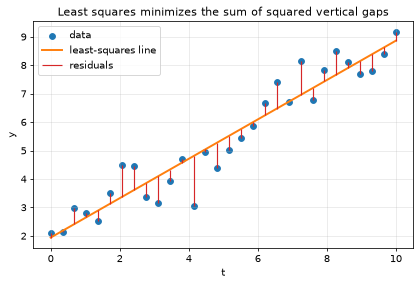

In [7]:
y_hat = A @ x_np
r = y - y_hat
print("A^T r =", np.round(A.T @ r, 10) + 0.0, "-> the residuals are perpendicular to both columns")
print("sum of residuals    =", round(r.sum(), 10) + 0.0, "(first column is all ones)")
print("residuals . inputs  =", round(r @ t, 10) + 0.0)
print("sum of squared residuals =", round(r @ r, 4))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(t, y, color="C0", label="data")
ax.plot(t, y_hat, color="C1", lw=2, label="least-squares line")
ax.vlines(t, y_hat, y, color="C3", lw=1.2, label="residuals")
ax.set_xlabel("t"); ax.set_ylabel("y"); ax.set_title("Least squares minimizes the sum of squared vertical gaps")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 5. Polynomial fits: underfit and overfit

More columns (here, powers of $t$) mean a bigger column space, so the projection can get closer to the data. We fit degrees 1, 3, and 9 to 12 noisy samples of a sine wave, and measure the error on both the training points and 100 fresh points.

degree  train RMSE  test RMSE
     1       0.542      0.538
     3       0.140      0.260
     9       0.008      0.311


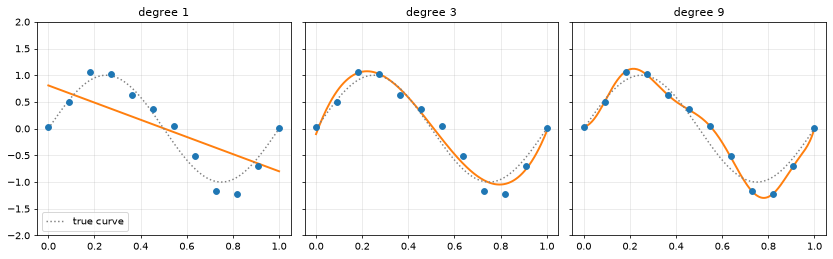

In [8]:
rng = np.random.default_rng(0)
t_train = np.linspace(0, 1, 12)
y_train = np.sin(2 * np.pi * t_train) + rng.normal(0, 0.25, size=12)
t_test = np.linspace(0, 1, 100) + 0.004
y_test = np.sin(2 * np.pi * t_test) + rng.normal(0, 0.25, size=100)

grid = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
print(f"{'degree':>6} {'train RMSE':>11} {'test RMSE':>10}")
for ax, degree in zip(axes, [1, 3, 9]):
    V_train = np.vander(t_train, degree + 1, increasing=True)
    coef = np.linalg.lstsq(V_train, y_train, rcond=None)[0]
    rmse = lambda V, y: np.sqrt(np.mean((V @ coef - y) ** 2))
    print(f"{degree:>6} {rmse(V_train, y_train):>11.3f} {rmse(np.vander(t_test, degree + 1, increasing=True), y_test):>10.3f}")
    ax.scatter(t_train, y_train, color="C0", zorder=3)
    ax.plot(grid, np.vander(grid, degree + 1, increasing=True) @ coef, color="C1", lw=2)
    ax.plot(grid, np.sin(2 * np.pi * grid), color="gray", ls=":", label="true curve")
    ax.set_ylim(-2, 2); ax.set_title(f"degree {degree}"); ax.grid(alpha=0.3)
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

Degree 1 underfits (both errors are large), degree 3 follows the sine wave, and degree 9 chases the noise: its training error is tiny but its error on fresh points is worse than degree 3. More columns always lower the training error, which is why it cannot be the only thing we check.

## 6. The normal equations lose accuracy

Forming $A^\top A$ **squares the condition number**, which measures how much a solve can magnify errors. For a nearly dependent matrix, such as a Vandermonde matrix of powers, that costs digits. Below, the data are generated exactly from known coefficients, so we can measure the error of each method.

In [9]:
t = np.linspace(0, 1, 20)
A = np.vander(t, 10, increasing=True)                 # columns 1, t, t^2, ..., t^9
true_coef = np.arange(1, 11, dtype=float)
y = A @ true_coef                                     # exact data: the right answer is known

print(f"cond(A)     = {np.linalg.cond(A):.1e}")
print(f"cond(A^T A) = {np.linalg.cond(A.T @ A):.1e}   (about the square of cond(A))")

Q, R = np.linalg.qr(A)
solutions = {
    "normal equations": np.linalg.solve(A.T @ A, A.T @ y),
    "QR": np.linalg.solve(R, Q.T @ y),
    "numpy lstsq": np.linalg.lstsq(A, y, rcond=None)[0],
}
for name, coef in solutions.items():
    print(f"{name:17s} largest error in the coefficients: {np.abs(coef - true_coef).max():.1e}")

cond(A)     = 3.8e+06
cond(A^T A) = 1.4e+13   (about the square of cond(A))
normal equations  largest error in the coefficients: 1.2e-03
QR                largest error in the coefficients: 7.1e-10
numpy lstsq       largest error in the coefficients: 1.7e-09


## 7. Collinear columns: many solutions

If one column is a combination of the others, $A^\top A$ is singular. There are then infinitely many least-squares solutions (any solution plus a nullspace vector). `lstsq` returns the one with the smallest length, the **minimum-norm solution**, which is also what the pseudoinverse gives.

In [10]:
X = np.array([[1, 2, 3],
              [2, 0, 2],
              [0, 1, 1],
              [3, 1, 4.]])                     # third column = first + second
y = np.array([6, 4, 2, 8.])

print("rank of X:", np.linalg.matrix_rank(X), "| rank of X^T X:", np.linalg.matrix_rank(X.T @ X), "(3 x 3, so singular)")
x_min, residual, rank, _ = np.linalg.lstsq(X, y, rcond=None)
print("lstsq answer:", x_min, "| fits exactly:", np.allclose(X @ x_min, y))
print("same as pinv(X) @ y:", np.allclose(x_min, np.linalg.pinv(X) @ y))

null_dir = sla.null_space(X).ravel()
other = x_min + 2.0 * null_dir                   # another solution with the same fit
print("other solution:", other, "| same predictions:", np.allclose(X @ other, X @ x_min))
print(f"lengths: minimum-norm {np.linalg.norm(x_min):.4f} < other {np.linalg.norm(other):.4f}")

rank of X: 2 | rank of X^T X: 2 (3 x 3, so singular)
lstsq answer: [0.6667 0.6667 1.3333] | fits exactly: True
same as pinv(X) @ y: True
other solution: [-0.488 -0.488  2.488] | same predictions: True
lengths: minimum-norm 1.6330 < other 2.5820


## 8. Projecting out a direction

Projection also removes things. To delete the component of a point along a direction $\mathbf{d}$ (a unit vector), subtract its projection: $\mathbf{x} - (\mathbf{x}\cdot\mathbf{d})\,\mathbf{d}$. What is left is perpendicular to $\mathbf{d}$. This is the idea behind removing a chosen direction from data or from embeddings.

largest dot product with d after removal: 0.0


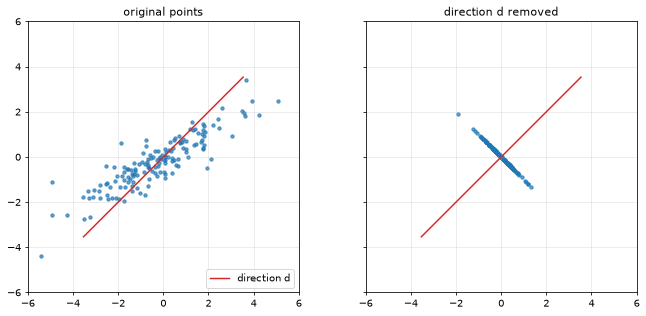

In [11]:
rng = np.random.default_rng(1)
cloud = rng.normal(size=(150, 2)) @ np.array([[2.0, 1.2], [0.0, 0.6]])    # a stretched, tilted cloud
d = np.array([1.0, 1.0]) / np.sqrt(2)                                     # the direction to remove

along = cloud @ d                                  # the component of every point along d
removed = cloud - np.outer(along, d)               # subtract it: (I - d d^T) applied to every point
print("largest dot product with d after removal:", round(np.abs(removed @ d).max(), 12))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, pts, title in [(axes[0], cloud, "original points"), (axes[1], removed, "direction d removed")]:
    ax.scatter(*pts.T, s=12, alpha=0.7)
    ax.plot([-5 * d[0], 5 * d[0]], [-5 * d[1], 5 * d[1]], color="C3", lw=1.5, label="direction d")
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

## Recap and next steps

* The **projection** of $\mathbf{b}$ onto a line is $\dfrac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{a}\cdot\mathbf{a}}\,\mathbf{a}$. Onto a column space it is $\mathbf{p} = A\hat{\mathbf{x}}$ with $A^\top A\,\hat{\mathbf{x}} = A^\top\mathbf{b}$, because the error must be perpendicular to every column.
* The projection matrix $P = A(A^\top A)^{-1}A^\top$ satisfies $P^2 = P$ and $P^\top = P$, and $I - P$ projects onto the perpendicular space.
* **Least squares** is the same problem: the closest point of the column space to $\mathbf{b}$ minimizes $\|A\mathbf{x} - \mathbf{b}\|^2$. The residual is perpendicular to every feature, and with an intercept column it sums to zero.
* More columns lower the training error but can overfit. In practice use `lstsq` or QR, not the inverse, because $A^\top A$ squares the condition number.
* With dependent columns there are many solutions, and `lstsq` returns the minimum-norm one.

**Try it yourself:** in section 5, change the noise level or the number of training points, and watch how the gap between train and test error for degree 9 moves. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Eigenvalues and Eigenvectors](../eigenvalues-and-eigenvectors/README.md).